# Contact angle distribution - Weibull

The Weibull distribution that we use in our code to distribute the contact angles is defined by taking a uniform random number $x$ normalized between [0,1], and then computing:
$$ \tilde\theta = \left[-\delta\log(1-x [1-e^{-1/\delta}])\right]^{1/\gamma}, $$
$$ \theta = \theta_{min}+\tilde\theta(\theta_{max}-\theta_{min}). $$
In order to compute the pdf of this distribution we can then isolate the variable $x$ in this definition:
$$ x=\frac{1-e^{-\frac{\tilde\theta^\gamma}{\delta}}}{1-e^{-\frac{1}{\delta}}}, $$
and then find it's derivative:
$$ p(\tilde\theta)\equiv\left|\frac{dx}{d\tilde\theta}\right|=\frac{\gamma}{\delta}\frac{\tilde\theta^{\gamma-1}e^{-\tilde\theta^\gamma/\delta}}{1-e^{-1/\delta}}. $$
That is already properly normalized:
$$ \int_0^1 p(\tilde\theta)d\tilde\theta = 1. $$
Below you can find a family of parameters and the plot of the distribution:

In [2]:
#!pip install gnuplot_kernel
%load_ext gnuplot_kernel

In [7]:
%gnuplot inline pngcairo size 800,400

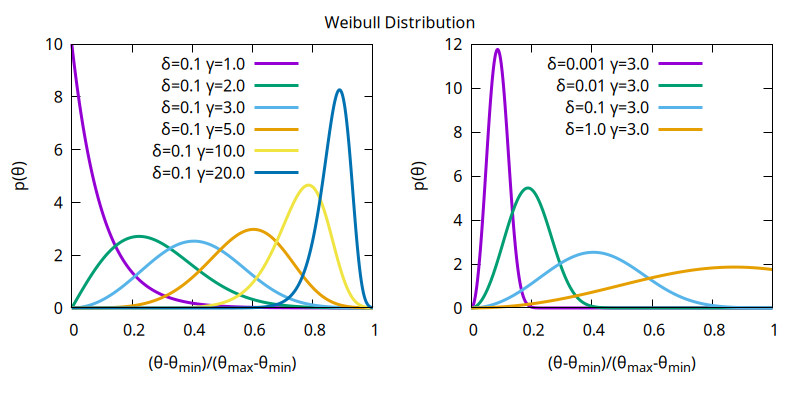

In [8]:
%%gnuplot

set samples 1000
set xlabel "({/Symbol q}-{/Symbol q}_{min})/({/Symbol q}_{max}-{/Symbol q}_{min})"
set ylabel "p({/Symbol q})"

set multiplot layout 1,2 title "Weibull Distribution"

set key top center
p [0:1][0:10] for[d in "0.1"] for[g in "1.0 2.0 3.0 5.0 10.0 20.0"] (g/d)*(x**(g-1.)*exp(-(x**g)/d))/(1.-exp(-1./d)) w l lw 3 t "{/Symbol d}=".d." {/Symbol g}=".g

set key top center
p [0:1][0:12] for[d in "0.001 0.01 0.1 1.0"] for[g in "3.0"] (g/d)*(x**(g-1.)*exp(-(x**g)/d))/(1.-exp(-1./d)) w l lw 3 t "{/Symbol d}=".d." {/Symbol g}=".g

unset multiplot

# Imports and constants

In [2]:
import numpy as np

In [3]:
g = 9.80665  # Gravitational acceleration

pw = 1000  # water_density
po = 900  # oil_density

sigma = 0.03  # interfacial_tension

miw = 0.00105  # water viscosity
mio = 0.00139  # oil viscosity

# test_drainage_entry_pc

Calculamos de acordo com a equação (3.7) do Valvatne a pressão de entrada na drenagem, dada por:
\begin{equation}
    P_c = \frac{\sigma \cos(\theta_r) (1+2\sqrt{\pi G})}{r}F_d(\theta_r, G, \beta),
\end{equation}

## 1 Duto Triangular

No caso do duto triangular, com $\beta_1<\beta_2<\beta_3$:

<p align="center">
    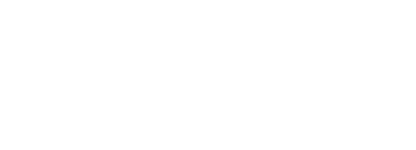
<p>

temos, das equações (3.11~3.16) do Valvatne:
\begin{equation}
    \begin{split}
        F_d&(\theta_r, G, \beta)=\frac{1+\sqrt{1+\frac{4GD}{\cos^2\theta_r}}}{1+2\sqrt{\pi G}},\\
        D&=S_1-2S_2\cos\theta_r+S_3,\\
        S_1&=\sum_{i=1}^{n} \frac{\cos\theta_r\cos(\theta_r+\beta_i)}{\sin\beta_i}+\theta_r+\beta_i-\frac{\pi}{2},\\
        S_2&=\sum_{i=1}^{n} \frac{\cos(\theta_r+\beta_i)}{\sin\beta_i},\\
        S_3&=2\sum_{i=1}^{n} \frac{\pi}{2}-\theta_r-\beta_i.\\
    \end{split}
\end{equation}
Onde n é o número total de cantos com meniscos que avançam, ou seja, para os quais $\beta<\frac{\pi}{2}-\theta_r$.

Usando os valores de:

In [5]:
G = 0.0443548387096774
r = 7.607076e-06
theta_r = 0.014092640613489886
shape = "TRIANGLE"
beta = np.array([0.35483625, 0.52387179, 0.69208829])

encontramos

In [6]:
S1 = sum([np.cos(theta_r)*np.cos(theta_r+betai)/np.sin(betai)+theta_r+betai-np.pi/2. for betai in beta if betai<np.pi/2-theta_r])
S2 = sum([np.cos(theta_r+betai)/np.sin(betai) for betai in beta if betai<np.pi/2-theta_r])
S3 = 2*sum([np.pi/2.-theta_r-betai for betai in beta if betai<np.pi/2-theta_r])
D = S1-2*S2*np.cos(theta_r)+S3
Fd = (1+np.sqrt(1+4*G*D/np.cos(theta_r)**2))/(1+2*np.sqrt(np.pi*G))
print("S1 =", S1)
print("S2 =", S2)
print("S3 =", S3)
print("D =", D)
print("Fd =", Fd)

S1 = 2.4936572243530355
S2 = 5.593527388020563
S3 = 6.19862945708844
D = -2.493657224353033
Fd = 1.000042071505461


In [7]:
Pc = sigma*np.cos(theta_r)*(1+2*np.sqrt(np.pi*G))/r*Fd
print("Pc = ", Pc)

Pc =  6887.581229783431


## 2 Duto quadrado

As mesmas fórmulas valem também para o duto quadrado, considerando n como o número de cantos com meniscos que avançam.

In [8]:
G = 0.0490196078431372
r = 9.092194e-06
theta_r = 0.013387853642248211
shape = "SQUARE" 
beta = np.array([0.35483625, 0.52387179, 0.69208829, 0.4])

In [9]:
S1 = sum([np.cos(theta_r)*np.cos(theta_r+betai)/np.sin(betai)+theta_r+betai-np.pi/2. for betai in beta if betai<np.pi/2-theta_r])
S2 = sum([np.cos(theta_r+betai)/np.sin(betai) for betai in beta if betai<np.pi/2-theta_r])
S3 = 2*sum([np.pi/2.-theta_r-betai for betai in beta if betai<np.pi/2-theta_r])
D = S1-2*S2*np.cos(theta_r)+S3
Fd = (1+np.sqrt(1+4*G*D/np.cos(theta_r)**2))/(1+2*np.sqrt(np.pi*G))
print("S1 =", S1)
print("S2 =", S2)
print("S3 =", S3)
print("D =", D)
print("Fd =", Fd)

S1 = 3.6877693650869023
S2 = 7.947319134442715
S3 = 8.517675125221187
D = -3.687769365086904
Fd = 0.8550255530897376


In [10]:
Pc = sigma*np.cos(theta_r)*(1+2*np.sqrt(np.pi*G))/r*Fd
print("Pc = ", Pc)

Pc =  5034.958069238446


## 3 Duto circular

Para o duto circular, Valvatne considera $F_d = 1$, então isso simplifica muito a conta:

In [11]:
G = 1.0 / (4.0 * np.pi)
r = 5.985215e-06
theta_r = 0.01630421505269301
shape = "CIRCLE"
beta = np.array([0.35483625])

In [12]:
Fd = 1
Pc = sigma*np.cos(theta_r)*(1+2*np.sqrt(np.pi*G))/r*Fd
print("Pc = ", Pc)

Pc =  10023.370146904406


# test\_imbibition\_entry\_pc DUVIDA 

Duvidas na função: 

calculate_imbibition_piston_like_displacement_pc

Valvatne calcula iterativamente, seção 3.3.1

# test_snap_off_pc

Existem diferentes condições nas quais um snap-off pode acontecer, considerando $\beta_1$ o canto com menor ângulo:

<table>
    <thead>
        <tr>
            <td>Function</td>
            <td>Condition</td>
            <td>Situation</td>
            <td>Pressure</td>
        </tr>
    </thead>
    <tbody>
        <tr>
            <td rowspan=2>calculate_waterwet_snapoff_pc</td>
            <td rowspan=2>Smooth advancing menisci ($\theta_a<\frac{\pi}{2}-\beta_1$)</td>
            <td>Two or more moving menisci</td>
            <td>$P_c=\frac{\sigma}{r}\left(\cos\theta_a-\frac{2\sin\theta_a}{\cot\beta_1+\cot\beta_2}\right)$</td>
        </tr>
        <tr>
            <td>One meniscus move and enconter a pinned one</td>
            <td>$P_c=\frac{\sigma}{r}\left(\frac{\cos\theta_a\cot\beta_1-\sin\theta_a+\cos\theta_{h,3}\cot\beta_3-\sin\theta_{h,3}}{\cot\beta_1+\cot\beta_3}\right)$ ou $P_c=\sigma\left(\frac{\cos\theta_a\cot\beta_1-\sin\theta_a}{r(\cot\beta_1+\cot\beta_2)-R_{min}(\cos\theta_r\cot\beta_2-\sin\theta_r)}\right)$</td>
        </tr>
        <tr>
            <td rowspan=2>calculate_oilwet_snapoff_pc</td>
            <td rowspan=2>Forced water invasion ($\theta_a\geq\frac{\pi}{2}-\beta_1$)</td>
            <td>$\theta_a\leq \pi-\beta_1$</td>
            <td>$P_c=\frac{\sigma\cos(\theta_a+\beta_1)}{R_{min}\cos(\theta_r+\beta_1)}$</td>
        </tr>
        <tr>
            <td>$\theta_a> \pi-\beta_1$</td>
            <td>$P_c=\frac{-\sigma}{R_{min}\cos(\theta_r+\beta_1)}$</td>
        </tr>
    </tbody>
</table>

In [76]:
def cot(x):
    return 1 / np.tan(x)

In [82]:
# Two or more moving menisci
r = 1e-06
theta_a = 0.3
theta_r = 0.3
pc = 5000
Rmin = sigma / pc
beta = np.array([0.35483625, 0.52387179, 0.69208829])
two_moving_pc = (sigma/r)*(np.cos(theta_a)-2*np.sin(theta_a)/(cot(beta[0])+cot(beta[1])))
single_moving_pc = sigma*(np.cos(theta_a) * cot(beta[0]) - np.sin(theta_a)) / (r*(cot(beta[0]) + cot(beta[2])) - Rmin * (np.cos(theta_r) * cot(beta[2]) - np.sin(theta_r)))
oil_pc1 = sigma*np.cos(theta_a+beta[0])/(Rmin*np.cos(theta_r+beta[0]))
oil_pc2 = -sigma/(Rmin*np.cos(theta_r+beta[0]))
print("Two moving Pc =", two_moving_pc)
print("Single moving Pc =", single_moving_pc)
print("Oil Pc 1 =", oil_pc1)
print("Oil Pc 2 =", oil_pc2)

Two moving Pc = 24657.452515046127
Single moving Pc = -55360.77990687415
Oil Pc 1 = 4999.999999999999
Oil Pc 2 = -6303.996350456403


In [94]:
# Single moving menisci
r = 1e-06
theta_a = 0.3
theta_r = 0.6
pc = 5000
Rmin = sigma / pc
beta = np.array([0.35483625, 0.52387179, 0.69208829])
two_moving_pc = (sigma/r)*(np.cos(theta_a)-2*np.sin(theta_a)/(cot(beta[0])+cot(beta[1])))
single_moving_pc = sigma*(np.cos(theta_a) * cot(beta[0]) - np.sin(theta_a)) / (r*(cot(beta[0]) + cot(beta[2])) - Rmin * (np.cos(theta_r) * cot(beta[2]) - np.sin(theta_r)))
oil_pc1 = sigma*np.cos(theta_a+beta[0])/(Rmin*np.cos(theta_r+beta[0]))
oil_pc2 = -sigma/(Rmin*np.cos(theta_r+beta[0]))
print("Two moving Pc =", two_moving_pc)
print("Single moving Pc =", single_moving_pc)
print("Oil Pc 1 =", oil_pc1)
print("Oil Pc 2 =", oil_pc2)

Two moving Pc = 24657.452515046127
Single moving Pc = 51933.37546591764
Oil Pc 1 = 6864.197934827633
Oil Pc 2 = -8654.375745992756


In [86]:
# Oil-wet 1
r = 1e-06
theta_a = 1.3
theta_r = 0.6
pc = 5000
Rmin = sigma / pc
beta = np.array([0.35483625, 0.52387179, 0.69208829])
two_moving_pc = (sigma/r)*(np.cos(theta_a)-2*np.sin(theta_a)/(cot(beta[0])+cot(beta[1])))
single_moving_pc = sigma*(np.cos(theta_a) * cot(beta[0]) - np.sin(theta_a)) / (r*(cot(beta[0]) + cot(beta[2])) - Rmin * (np.cos(theta_r) * cot(beta[2]) - np.sin(theta_r)))
oil_pc1 = sigma*np.cos(theta_a+beta[0])/(Rmin*np.cos(theta_r+beta[0]))
oil_pc2 = -sigma/(Rmin*np.cos(theta_r+beta[0]))
print("Two moving Pc =", two_moving_pc)
print("Single moving Pc =", single_moving_pc)
print("Oil Pc 1 =", oil_pc1)
print("Oil Pc 2 =", oil_pc2)

Two moving Pc = -5025.8469923530565
Single moving Pc = -5496.254196811559
Oil Pc 1 = -726.4572419676624
Oil Pc 2 = -8654.375745992756


In [93]:
# Oil-wet 1
r = 1e-06
theta_a = 2.9
theta_r = 0.3
pc = 5000
Rmin = sigma / pc
beta = np.array([0.35483625, 0.52387179, 0.69208829])
two_moving_pc = (sigma/r)*(np.cos(theta_a)-2*np.sin(theta_a)/(cot(beta[0])+cot(beta[1])))
single_moving_pc = sigma*(np.cos(theta_a) * cot(beta[0]) - np.sin(theta_a)) / (r*(cot(beta[0]) + cot(beta[2])) - Rmin * (np.cos(theta_r) * cot(beta[2]) - np.sin(theta_r)))
oil_pc1 = sigma*np.cos(theta_a+beta[0])/(Rmin*np.cos(theta_r+beta[0]))
oil_pc2 = -sigma/(Rmin*np.cos(theta_r+beta[0]))
print("Two moving Pc =", two_moving_pc)
print("Single moving Pc =", single_moving_pc)
print("Oil Pc 1 =", oil_pc1)
print("Oil Pc 2 =", oil_pc2)

Two moving Pc = -32369.232169818075
Single moving Pc = 69351.75496718571
Oil Pc 1 = -6263.61795153958
Oil Pc 2 = -6303.996350456403


# test_b

No "Piston-like displacement" o menisco fica inicialmente pinado em um canto com uma distancia $b_i$, definida por:

\begin{equation}
b_i=R_{min}\frac{\cos(\theta_r+\beta_i)}{\beta_i}
\end{equation}

<p align="center">
    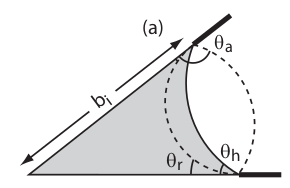
<p>

Quando o menisco é plano, ou seja $\beta_i+\theta_r=\pi/2$, o $\cos$ vale zero. 

DUVIDA: Por que essa distância deveria ser zero? O que deveria acontecer se $\theta_r>\pi/2-\beta_i$ (oilwet)?

Por enquanto assumimos que $b_i$ fica em zero.

## 1 Triangular

In [37]:
max_pc = 40000
beta = np.array([0.35483625, 0.52387179, 0.69208829])
theta = np.full(len(beta), 0.014092640613489886)
Rmin = sigma/max_pc

In [38]:
b = [0 if theta[i] + beta[i] > np.pi / 2 else Rmin * np.cos(theta[i] + beta[i]) / np.sin(beta[i]) for i in range(len(beta))]
print("b =", b)

b = [2.0134181614878903e-06, 1.2875214062705223e-06, 8.942059732570099e-07]


## 2 Square

In [39]:
max_pc = 40000
beta = np.array([0.78539816, 0.78539816, 0.78539816, 0.78539816])
theta = np.full(len(beta), 0.014092640613489886)
Rmin = sigma/max_pc

In [40]:
b = [0 if theta[i] + beta[i] > np.pi / 2 else Rmin * np.cos(theta[i] + beta[i]) / np.sin(beta[i]) for i in range(len(beta))]
print("b =", b)

b = [7.393563997741031e-07, 7.393563997741031e-07, 7.393563997741031e-07, 7.393563997741031e-07]


# test_hinging_contact_angle

No caso do "Piston-like displacement", o ângulo do menisco pode se alterar sem sair do lugar $b_i$ onde está pinado, essa mudança no ângulo de contato é dada por: 

\begin{equation}
\theta_{h,i}=\arccos\left(\frac{b_i\sin\beta_i}{R}\right)-\beta_i
\end{equation}

Além disso, o ângulo articulado (*hinging*) precisa estar limitado pelos valores de recuo (*receding*) e avanço (*advancing*) $\theta_r<\theta_{h,i}<\theta_a$ escolhidos no início da simulação. 

In [43]:
pc = 5000
beta = np.array([0.35483625, 0.52387179, 0.69208829])
b = np.array([2.0134182e-06, 1.2875214e-06, 8.9420597e-07])
n_corners = len(beta)
theta_r = np.full(n_corners, 0.011)
theta_a = np.full(n_corners, 0.014)
R = sigma/pc

In [50]:
theta_h = [np.clip(np.arccos(b[i]*np.sin(beta[i])/R)-beta[i],theta_r[i],theta_a[i]) for i in range(n_corners)]
print("theta_h =", theta_h)

theta_h = [0.014, 0.014, 0.014]


# test_conductance

Para medir a condutância para uma sequência de poro-garganta-poro, fazemos uma média harmônica de cada condutância individual, de acordo com a equação (3.43) de Valvatne:

\begin{equation}
\frac{L_{ij}}{g_{p,ij}}=\frac{L_i}{g_{p,i}}+\frac{L_t}{g_{p,t}}+\frac{L_j}{g_{p,j}}
\end{equation}

In [97]:
A = np.empty(3, dtype=np.float64)
A[0] = 3.2616286606601026e-10
A[1] = 0.85423594305093e-10
A[2] = 59.5109522864946e-10
G = np.empty(3, dtype=np.float64)
G[0] = 0.0443548387096774
G[1] = 0.07258065
G[2] = 0.0354226214781543
L = np.empty(3, dtype=np.float64)
L[0] = 7.607076e-06
L[1] = 2.620349e-05
L[2] = 2.903814e-05
shape = np.empty(3, dtype=np.float64)
shape[0] = 0
shape[1] = 2
shape[2] = 0

## 1. Single phase

Para o caso de fluxo laminar single-phase, pode-se encontrar analiticamente a fórmula de Hagen-Poiseuille:
\begin{equation}
g_p=k\frac{A^2G}{\mu_p},
\end{equation}
onde $k=\frac{1}{2}=0.5$ para dutos circulares, $k=\frac{3}{5}=0.6$ para triângulos equiláteros e $k=0.5623$ para quadrados. Para o duto circular, triangulos e quadrados equiláteros essa fórmula é exata, no entanto Øren mostra, a partir de simulações numéricas, que essas constantes são aproximadamente as mesmas para triângulos e quadrados irregulares também.

In [102]:
conductance_water = 1 / (
    L[0] / (0.6 * A[0] ** 2 * G[0] / miw)
    + L[1] / (0.5 * A[1] ** 2 * G[1] / miw)
    + L[2] / (0.6 * A[2] ** 2 * G[2] / miw)
)
conductance_oil = 1 / (
    L[0] / (0.6 * A[0] ** 2 * G[0] / mio)
    + L[1] / (0.5 * A[1] ** 2 * G[1] / mio)
    + L[2] / (0.6 * A[2] ** 2 * G[2] / mio)
)
print("conductance_water =", conductance_water)
print("conductance_oil =", conductance_oil)

conductance_water = 9.366933989647119e-15
conductance_oil = 7.0757415029708445e-15


## 2. Multiphase

No caso multifasico é mais complexo, uma vez que os ângulos dos cantos vão interferir em como se dará a interação óleo/água. Por conta disso, as correlações são propostas empiricamente a partir de métodos de simulação.

### 2.1. Water layers

Valvatne assume a seguinte correlação para as camadas de água:

\begin{equation}
\begin{split}
A_c&=\left(\frac{b_i\sin\beta}{\cos(\theta_i+\beta)}\right)^2\left(\frac{\cos\theta_i\cos(\theta_i+\beta)}{\sin\beta}+\theta_i+\beta-\frac{\pi}{2}\right)\\
G_c&=\frac{A_c}{4b_i^2\left(1-\frac{\sin\beta}{\cos(\theta_i+\beta)}\left(\theta_i+\beta-\frac{\pi}{2}\right)\right)^2}\\
G^*&=\frac{\sin\beta\cos\beta}{4(1+\sin\beta)^2}\\
C&=0.364+0.28\frac{G^*}{G_c}\\
g_{pc}&=C\frac{A_c^2G_c}{\mu_p}
\end{split}
\end{equation}

Abaixo calculamos para um caso específico:

In [125]:
beta = np.array(
    [
        [0.35483625, 0.52387179, 0.69208829, 0],
        [0.35483625, 0.52387179, 0.69208829, 0],
        [0.78539816, 0.78539816, 0.78539816, 0.78539816],
    ]
)
n_corners = [3, 3, 4]
b = np.array(
    [
        [2.0134182e-06, 1.2875214e-06, 8.9420597e-07, 0],
        [2.0134182e-06, 1.2875214e-06, 8.9420597e-07, 0],
        [7.398922e-07, 7.398922e-07, 7.398922e-07, 7.398922e-07]
    ]
)
theta_h = np.array(
    [
        [1.099105, 0.9393731, 0.7834584, 0],
        [1.099105, 0.9393731, 0.7834584, 0], 
        [0.6980902, 0.6980902, 0.6980902, 0.6980902]
    ]
)

In [128]:
def conductivity(b, beta, theta):
    Ac = ((b * np.sin(beta)) / np.cos(theta + beta)) ** 2 * (
        np.cos(theta) * np.cos(theta + beta) / np.sin(beta) + theta + beta - np.pi / 2
    )
    Gc = Ac / (
        4 * b ** 2 * (1 - np.sin(beta) / np.cos(theta + beta) * (theta + beta - np.pi / 2)) ** 2
    )
    G2 = np.sin(beta) * np.cos(beta) / (4 * (1 + np.sin(beta)) ** 2)
    Cw = 0.364 + 0.28 * (G2 / Gc)
    return Cw * (Ac**2 * Gc / miw)

# Mede condutividades
gw = np.zeros(len(n_corners))
for elems in range(len(n_corners)): # poro-garganta-poro
    for i in range(int(n_corners[elems])): # cantos de cada elemento
        # soma sobre as condutividades pq os cantos representam dutos em paralelo
        # ref. parágrafo após eq (19) em Oren, 1997
        gw[elems] += conductivity(b[elems,i], beta[elems,i], theta_h[elems,i])
print("condutividades =", gw)

# Mede condutância do conjunto poro-garganta-poro : representam dutos em série
G = 1/sum([L[i]/gw[i] for i in range(len(L))])
print("condutância =", G)

condutividades = [6.18991665e-23 6.18991665e-23 6.75806137e-24]
condutância = 2.0648208672078985e-19


### 2.2. Oil layers

Para a camada de óleo a condutividade é calculada diferente:

\begin{equation}
\begin{split}
\tilde b_i&=\frac{b_i}{b_o}\\
\tilde A_o&=\left(\frac{\sin\beta}{\cos(\theta_o-\beta)}\right)^2\left(\frac{\cos\theta_o\cos(\theta_o-\beta)}{\sin\beta}-\theta_o+\beta+\frac{\pi}{2}\right)\\
\tilde A_i&=\left(\frac{\tilde b_i\sin\beta}{\cos(\theta_i+\beta)}\right)^2\left(\frac{\cos\theta_i\cos(\theta_i+\beta)}{\sin\beta}+\theta_i+\beta-\frac{\pi}{2}\right)\\
\tilde A_l&=\tilde A_o-\tilde A_i\\
\tilde L_{oow}&=\frac{2\sin\beta}{\cos(\theta_o-\beta)}\left(\frac{\pi}{2}-\theta_o+\beta\right)\\
\tilde L_{iow}&=\frac{2\tilde b_i\sin\beta}{\cos(\theta_i+\beta)}\left(\frac{\pi}{2}-\theta_i-\beta\right)\\
G_l&=\frac{\tilde A_l}{(\tilde L_{oow}+\tilde L_{iow}+2(1-\tilde b_i))^2}\\
\ln\tilde g_l&=a_1\ln^2(\tilde A_l^3 G_l)+a_2\ln(\tilde A_l^3 G_l)+a_3\\
g_{pl}&=\frac{b_o^4 \tilde g_l}{\mu_p}
\end{split}
\end{equation}

onde as constantes $a_{1,2,3}$ são dadas pela tabela:

<p align="center">
    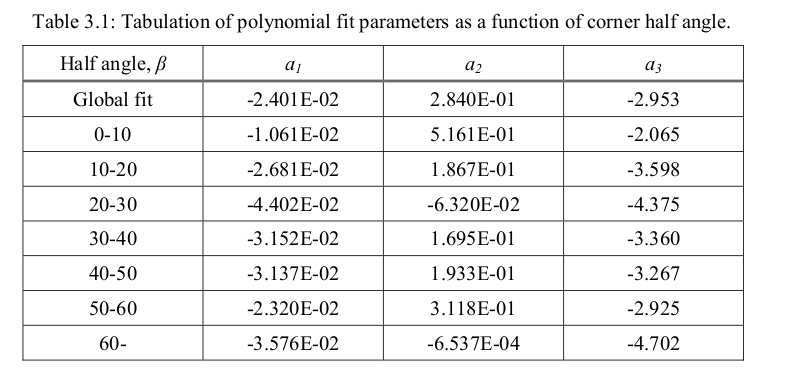
<p>

In [132]:
beta = np.array(
    [
        [0.35483625, 0.52387179, 0.69208829],
        [0.35483625, 0.52387179, 0.69208829],
        [0.35483625, 0.52387179, 0.69208829],
    ]
)
n_corners = [3, 3, 3]
b = np.array(
    [
        [2.0134182e-06, 1.2875214e-06, 8.9420597e-07],
        [2.0134182e-06, 1.2875214e-06, 8.9420597e-07],
        [2.0134182e-06, 1.2875214e-06, 8.9420597e-07],
    ]
)
bo = np.array(
    [
        [8.9420597e-07, 2.0134182e-06, 1.2875214e-06],
        [8.9420597e-07, 2.0134182e-06, 1.2875214e-06],
        [8.9420597e-07, 2.0134182e-06, 1.2875214e-06],
    ]
)
theta_h = np.array(
    [[0.35483625, 0.52387179, 0.1], [0.35483625, 0.52387179, 0.1], [0.35483625, 0.52387179, 0.1]]
)
theta_a = np.array(
    [[0.35483625, 0.52387179, 0.1], [0.35483625, 0.52387179, 0.1], [0.35483625, 0.52387179, 0.1]]
)

In [141]:
def get_tabulated_conductance_constants(beta):
    if beta < 0.17453292519943295:  # 10 degrees
        a1, a2, a3 = -1.061e-02, 5.161e-01, -2.065
    elif beta < 0.3490658503988659:  # 20 degrees
        a1, a2, a3 = -2.681e-02, 1.867e-01, -3.598
    elif beta < 0.5235987755982988:  # 30 degrees
        a1, a2, a3 = -4.402e-02, -6.320e-02, -4.375
    elif beta < 0.6981317007977318:  # 40 degrees
        a1, a2, a3 = -3.152e-02, 1.695e-01, -3.360
    elif beta < 0.8726646259971648:  # 50 degrees
        a1, a2, a3 = -3.137e-02, 1.933e-01, -3.267
    elif beta < 1.0471975511965976:  # 60 degrees
        a1, a2, a3 = -2.320e-02, 3.118e-01, -2.925
    else:
        a1, a2, a3 = -3.576e-02, -6.537e-04, -4.702
    return a1, a2, a3
    
def conductivity(bi, bo, beta, theta_o, theta_i):
    a1, a2, a3 = get_tabulated_conductance_constants(beta)

    bi_tilde = bi/bo
    Ao = (np.sin(beta) / np.cos(theta_o - beta)) ** 2 * (
        np.cos(theta_o) * np.cos(theta_o - beta) / np.sin(beta) - theta_o + beta + np.pi / 2
    )
    Ai = ((bi_tilde * np.sin(beta)) / np.cos(theta_i + beta)) ** 2 * (
        np.cos(theta_i) * np.cos(theta_i + beta) / np.sin(beta) + theta_i + beta - np.pi / 2
    )
    Al = Ao-Ai
    Loow = (2*np.sin(beta)/np.cos(theta_o-beta))*(np.pi/2-theta_o+beta)
    Liow = (2*bi_tilde*np.sin(beta)/np.cos(theta_i+beta))*(np.pi/2-theta_i-beta)
    Gl = Al / (
        Loow+Liow+2*(1-bi_tilde)
    )**2
    gl = np.exp(a1 * np.log(Al**3 * Gl) ** 2 + a2 * np.log(Al**3 * Gl) + a3)
    
    return bo**4 * gl/mio

# Mede condutividades
go = np.zeros(len(n_corners))
for elems in range(len(n_corners)): # poro-garganta-poro
    for i in range(int(n_corners[elems])): # cantos de cada elemento
        # soma sobre as condutividades pq os cantos representam dutos em paralelo
        # ref. parágrafo após eq (19) em Oren, 1997
        go[elems] += conductivity(b[elems,i], bo[elems,i], beta[elems,i], theta_h[elems,i], theta_a[elems,i])
print("condutividades =", go)

# Mede condutância do conjunto poro-garganta-poro : representam dutos em série
G = 1/sum([L[i]/go[i] for i in range(len(L))])
print("condutância =", G)

condutividades = [2.10581055e-22 2.10581055e-22 2.10581055e-22]
condutância = 3.3506028719041424e-18
